# Task 11: Agreement versus exposure level

Do AIOE, Frey–Osborne, and Eloundou disagree more about the most-exposed occupations than about the least-exposed ones? This notebook answers that on the fixed 663-occupation sample from Task 9, once with Eloundou GPT-4 beta and once with Eloundou human beta.

- **Exposure band:** equal-count quintile of the *consensus* rank, the mean of an occupation's percentile ranks. Band 1 = least exposed, band 5 = most exposed.
- **Disagreement:** per-occupation spread of the three percentile ranks: standard deviation, range (max − min), and the three pairwise absolute rank gaps.
- **Permutation baseline:** because ranks are bounded between 0 and 1, an occupation can only have a consensus near 0 or 1 if all its ranks are near the same end. Spread therefore shrinks at the extreme bands *mechanically*. To separate that from real agreement, each index's ranks are shuffled independently 1,000 times and the band medians are recomputed. Observed medians are compared with that no-agreement baseline.

Run top to bottom from the repository root or `notebooks/`, using dependencies in `requirements.txt`. Results are descriptive, unweighted occupation-level associations. They do not show that exposure causes disagreement, and exposure is not a prediction of job loss.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats

project_folder = Path('..') if Path('../data/datasets/processed').is_dir() else Path('.')
processed_folder = project_folder / 'data/datasets/processed'
figures_folder = project_folder / 'figures'
sample_path = processed_folder / 'agreement_analysis_sample.csv'
source_sha256 = hashlib.sha256(sample_path.read_bytes()).hexdigest()
sample = pd.read_csv(sample_path, dtype={'soc2018': 'string'})
sample = sample.sort_values('soc2018', ignore_index=True)

label_sources = {'gpt4': 'GPT-4', 'human': 'human'}
eloundou_columns = {
    'gpt4': ('dv_rating_beta', 'rank_elo_dv'),
    'human': ('human_rating_beta', 'rank_elo_hum'),
}
score_to_rank = {
    'aioe': 'rank_aioe', 'fo_prob': 'rank_fo',
    'dv_rating_beta': 'rank_elo_dv', 'human_rating_beta': 'rank_elo_hum',
}
assert len(sample) == 663, f'Expected the fixed 663 occupations; found {len(sample)}'
assert sample['soc2018'].notna().all() and sample['soc2018'].is_unique
assert sample['included_in_analysis'].eq(True).all()
assert sample[[*score_to_rank, *score_to_rank.values()]].notna().all().all()
for score, rank in score_to_rank.items():
    np.testing.assert_allclose(
        sample[rank], sample[score].rank(method='average', ascending=True, pct=True),
        rtol=0, atol=1e-12,
    )

N_BANDS = 5
N_PERMUTATIONS = 1000
SEED = 11
MIN_BAND_SIZE = 30         # bands smaller than this are flagged as sparse
TIE_HEAVY_SHARE = 0.25     # band flagged when one repeated raw score covers more than this share of it

print(f'Fixed sample verified: {len(sample)} unique occupations.')
print(f'Input SHA-256: {source_sha256}')
print(f'pandas {pd.__version__}; NumPy {np.__version__}; SciPy {scipy.__version__}')

Fixed sample verified: 663 unique occupations.
Input SHA-256: 7f0c606895d080d913ed147c8436a60ea61cafeebd1dfe3a9bba907509f782ee
pandas 2.3.3; NumPy 2.5.4; SciPy 1.18.1


## 1. Exposure bands and per-occupation disagreement

**Band rule (recorded for the write-up):** consensus = unweighted mean of the occupation's percentile ranks; occupations are sorted by consensus and split into five equal-count bands (sizes 133, 133, 133, 132, 132). Exact consensus ties are broken by SOC code order.

Two consensus rules are run:

- **`all_three` (primary):** mean of AIOE, Frey–Osborne, and Eloundou ranks, as the task specifies.
- **`aioe_eloundou` (sensitivity):** mean of AIOE and Eloundou only. Task 10 found Frey–Osborne is *negatively* correlated with both modern indices, so including it pulls the consensus toward the middle. This rule bands occupations by modern AI exposure alone.

Disagreement is always measured across all three indices, whichever rule defines the bands.

In [2]:
pairs = {'gap_aioe_fo': (0, 1), 'gap_aioe_elo': (0, 2), 'gap_fo_elo': (1, 2)}
metrics = ['rank_sd', 'rank_range', *pairs]
consensus_rules = {'all_three': [0, 1, 2], 'aioe_eloundou': [0, 2]}

def rank_matrix(label_source):
    # Columns: AIOE, Frey–Osborne, Eloundou (for this label source).
    return sample[['rank_aioe', 'rank_fo', eloundou_columns[label_source][1]]].to_numpy()

def disagreement(ranks):
    measures = {
        'rank_sd': ranks.std(axis=1, ddof=0),
        'rank_range': ranks.max(axis=1) - ranks.min(axis=1),
    }
    for name, (i, j) in pairs.items():
        measures[name] = np.abs(ranks[:, i] - ranks[:, j])
    return measures

def assign_bands(consensus):
    # Stable sort keeps SOC order for exact ties, so banding is deterministic.
    order = np.argsort(consensus, kind='stable')
    bands = np.empty(len(consensus), dtype=int)
    for band, rows in enumerate(np.array_split(order, N_BANDS), start=1):
        bands[rows] = band
    return bands

frames = []
for label_source in label_sources:
    ranks = rank_matrix(label_source)
    frame = sample[['soc2018', 'title']].copy()
    frame.insert(0, 'label_source', label_source)
    frame[['rank_aioe', 'rank_fo', 'rank_eloundou']] = ranks
    for rule, columns in consensus_rules.items():
        consensus = ranks[:, columns].mean(axis=1)
        frame[f'consensus_{rule}'] = consensus
        frame[f'band_{rule}'] = assign_bands(consensus)
    for metric, values in disagreement(ranks).items():
        frame[metric] = values
    frames.append(frame)
occupations = pd.concat(frames, ignore_index=True)

assert occupations.groupby('label_source').size().eq(663).all()
assert occupations['rank_sd'].between(0, 0.5).all()
assert occupations['rank_range'].between(0, 1).all()
for rule in consensus_rules:
    sizes = occupations.groupby(['label_source', f'band_{rule}']).size()
    assert sizes.between(132, 133).all() and len(sizes) == 2 * N_BANDS
    band_order = occupations.groupby(['label_source', f'band_{rule}'])[f'consensus_{rule}'].agg(['min', 'max'])
    for label_source in label_sources:
        b = band_order.loc[label_source]
        assert (b['max'].iloc[:-1].to_numpy() <= b['min'].iloc[1:].to_numpy()).all(), 'Bands overlap'

occupations.head()

,label_source,soc2018,title,rank_aioe,rank_fo,rank_eloundou,consensus_all_three,band_all_three,consensus_aioe_eloundou,band_aioe_eloundou,rank_sd,rank_range,gap_aioe_fo,gap_aioe_elo,gap_fo_elo
0,gpt4,11-1011,Chief Executives,0.924585,0.100302,0.793363,0.606083,4,0.858974,5,0.361632,0.824284,0.824284,0.131222,0.693062
1,gpt4,11-1021,General and Operations Managers,0.660633,0.282051,0.733032,0.558572,4,0.696833,4,0.197751,0.450980,0.378582,0.072398,0.450980
2,gpt4,11-2011,Advertising and Promotions Managers,0.901961,0.181750,0.726998,0.603570,4,0.814480,5,0.306705,0.720211,0.720211,0.174962,0.545249
3,gpt4,11-2021,Marketing Managers,0.912519,0.089744,0.776018,0.592760,4,0.844268,5,0.360025,0.822775,0.822775,0.136501,0.686275
4,gpt4,11-2022,Sales Managers,0.876320,0.083710,0.693816,0.551282,4,0.785068,4,0.338914,0.792609,0.792609,0.182504,0.610106


## 2. Permutation baseline

Each permutation shuffles the three rank columns independently, which destroys any real agreement while keeping each index's distribution (including its ties). Bands and disagreement medians are then recomputed exactly as above. The 2.5th–97.5th percentiles of the 1,000 permuted medians form the baseline interval. An observed median **below** it means the indices agree more than chance in that band; **above** means they disagree more than chance.

`null_p` is a two-sided permutation p-value for that one band and metric. These are not adjusted for the many band × metric comparisons, so treat them as descriptive.

In [3]:
rng = np.random.default_rng(SEED)
null_medians = {
    (label_source, rule): np.empty((N_PERMUTATIONS, N_BANDS, len(metrics)))
    for label_source in label_sources for rule in consensus_rules
}
for label_source in label_sources:
    ranks = rank_matrix(label_source)
    for k in range(N_PERMUTATIONS):
        shuffled = np.column_stack([rng.permutation(ranks[:, j]) for j in range(3)])
        measures = disagreement(shuffled)
        stacked = np.column_stack([measures[m] for m in metrics])
        for rule, columns in consensus_rules.items():
            bands = assign_bands(shuffled[:, columns].mean(axis=1))
            for band in range(1, N_BANDS + 1):
                null_medians[(label_source, rule)][k, band - 1] = np.median(stacked[bands == band], axis=0)

for draws in null_medians.values():
    assert np.isfinite(draws).all()
print(f'{N_PERMUTATIONS} permutations per label source (seed {SEED}).')

1000 permutations per label source (seed 11).


## 3. Band summary with tie and sparsity flags

One row per label source × consensus rule × band × metric. Tie shares come from the *raw* scores: for each index, the share of the band's occupations that sit on that band's single most common value. Frey–Osborne probabilities and Eloundou shares are coarse, so some ties are everywhere; the flag marks bands where one repeated value covers more than a quarter of the band, so its occupations share one average rank and gaps there are less precise.

In [4]:
raw_score_columns = {
    'gpt4': {'aioe': 'aioe', 'fo': 'fo_prob', 'eloundou': 'dv_rating_beta'},
    'human': {'aioe': 'aioe', 'fo': 'fo_prob', 'eloundou': 'human_rating_beta'},
}
modal_share = lambda values: values.value_counts(normalize=True).iloc[0]

rows = []
for (label_source, rule), draws in null_medians.items():
    occ = occupations.loc[occupations['label_source'].eq(label_source)].reset_index(drop=True)
    for band, group in occ.groupby(f'band_{rule}'):
        tie_shares = pd.Series({
            index: modal_share(sample.loc[group.index, column])
            for index, column in raw_score_columns[label_source].items()
        })
        consensus = group[f'consensus_{rule}']
        for m, metric in enumerate(metrics):
            values = group[metric]
            observed = values.median()
            null = draws[:, band - 1, m]
            centre = null.mean()
            null_lo, null_hi = np.percentile(null, [2.5, 97.5])
            rows.append({
                'label_source': label_source, 'consensus_rule': rule, 'band': band,
                'n': len(group),
                'consensus_min': consensus.min(), 'consensus_median': consensus.median(),
                'consensus_max': consensus.max(),
                'metric': metric, 'median': observed,
                'q1': values.quantile(0.25), 'q3': values.quantile(0.75), 'mean': values.mean(),
                'null_median': np.median(null), 'null_lo': null_lo, 'null_hi': null_hi,
                'null_p': (1 + np.sum(np.abs(null - centre) >= abs(observed - centre))) / (N_PERMUTATIONS + 1),
                'vs_null': 'above' if observed > null_hi else 'below' if observed < null_lo else 'within',
                'tie_share_aioe': tie_shares['aioe'], 'tie_share_fo': tie_shares['fo'],
                'tie_share_eloundou': tie_shares['eloundou'],
                'sparse_flag': len(group) < MIN_BAND_SIZE,
                'tie_heavy_flag': bool(tie_shares.max() > TIE_HEAVY_SHARE),
            })
band_summary = pd.DataFrame(rows)
assert len(band_summary) == len(label_sources) * len(consensus_rules) * N_BANDS * len(metrics)
assert not band_summary.isna().any().any()

view = band_summary.loc[band_summary['metric'].eq('rank_sd'),
    ['label_source', 'consensus_rule', 'band', 'n', 'median', 'null_lo', 'null_hi', 'vs_null',
     'tie_share_fo', 'tie_share_eloundou', 'tie_heavy_flag']]
view.round(3)

,label_source,consensus_rule,band,n,median,null_lo,null_hi,vs_null,tie_share_fo,tie_share_eloundou,tie_heavy_flag
0,gpt4,all_three,1,133,0.205,0.147,0.182,above,0.053,0.293,True
5,gpt4,all_three,2,133,0.206,0.225,0.266,below,0.053,0.045,False
10,gpt4,all_three,3,133,0.201,0.241,0.281,below,0.045,0.023,False
15,gpt4,all_three,4,132,0.260,0.225,0.266,within,0.053,0.038,False
20,gpt4,all_three,5,132,0.137,0.147,0.185,below,0.114,0.098,False
25,gpt4,aioe_eloundou,1,133,0.259,0.166,0.217,above,0.060,0.331,True
30,gpt4,aioe_eloundou,2,133,0.170,0.203,0.241,below,0.053,0.045,False
35,gpt4,aioe_eloundou,3,133,0.141,0.222,0.263,below,0.060,0.030,False
40,gpt4,aioe_eloundou,4,132,0.218,0.202,0.241,within,0.045,0.091,False
45,gpt4,aioe_eloundou,5,132,0.264,0.167,0.212,above,0.068,0.053,False


In [5]:
gap_view = band_summary.loc[band_summary['metric'].str.startswith('gap')].pivot_table(
    index=['label_source', 'consensus_rule', 'band'], columns='metric', values='median')
gap_view.round(3)

metric                            gap_aioe_elo  gap_aioe_fo  gap_fo_elo
label_source consensus_rule band                                       
gpt4         aioe_eloundou  1            0.075        0.531       0.533
                            2            0.112        0.348       0.331
                            3            0.087        0.305       0.259
                            4            0.101        0.433       0.417
                            5            0.109        0.558       0.520
             all_three      1            0.080        0.439       0.434
                            2            0.101        0.436       0.397
                            3            0.094        0.440       0.399
                            4            0.106        0.516       0.540
                            5            0.109        0.266       0.258
human        aioe_eloundou  1            0.065        0.528       0.537
                            2            0.100        0.365       0.364
                            3            0.088        0.276       0.265
                            4            0.122        0.433       0.409
                            5            0.096        0.595       0.571
             all_three      1            0.070        0.439       0.416
                            2            0.094        0.385       0.391
                            3            0.097        0.436       0.413
                            4            0.112        0.544       0.532
                            5            0.095        0.270       0.292

## 4. Does disagreement rise among the most-exposed occupations?

Three checks on rank SD, per label source and consensus rule:

- Spearman correlation between consensus and rank SD across all 663 occupations.
- Kruskal–Wallis test that rank SD differs across the five bands.
- Mann–Whitney test of band 5 against bands 1–4, with the band-5 permutation result.

The classical tests compare *observed* bands with each other, so they include the mechanical ceiling effect. The permutation column is the comparison that accounts for it.

In [6]:
test_rows = []
for label_source in label_sources:
    occ = occupations.loc[occupations['label_source'].eq(label_source)]
    for rule in consensus_rules:
        band = occ[f'band_{rule}']
        rho, rho_p = stats.spearmanr(occ[f'consensus_{rule}'], occ['rank_sd'])
        h, kw_p = stats.kruskal(*[g['rank_sd'] for _, g in occ.groupby(band)])
        top, rest = occ.loc[band.eq(N_BANDS), 'rank_sd'], occ.loc[band.lt(N_BANDS), 'rank_sd']
        u, mw_p = stats.mannwhitneyu(top, rest, alternative='two-sided')
        top_row = band_summary.set_index(['label_source', 'consensus_rule', 'band', 'metric']).loc[
            (label_source, rule, N_BANDS, 'rank_sd')]
        test_rows.append({
            'label_source': label_source, 'consensus_rule': rule,
            'spearman_rho': rho, 'spearman_p': rho_p, 'kruskal_h': h, 'kruskal_p': kw_p,
            'top_band_median_sd': top.median(), 'other_bands_median_sd': rest.median(),
            'mannwhitney_p': mw_p,
            'top_null_lo': top_row['null_lo'], 'top_null_hi': top_row['null_hi'],
            'top_vs_null': top_row['vs_null'], 'top_null_p': top_row['null_p'],
        })
tests = pd.DataFrame(test_rows)
tests.round(4)

,label_source,consensus_rule,spearman_rho,spearman_p,kruskal_h,kruskal_p,top_band_median_sd,other_bands_median_sd,mannwhitney_p,top_null_lo,top_null_hi,top_vs_null,top_null_p
0,gpt4,all_three,-0.0664,0.0875,45.1791,0.0,0.1371,0.2177,0.000,0.1473,0.1852,below,0.005
1,gpt4,aioe_eloundou,-0.0387,0.3196,88.3763,0.0,0.2640,0.1993,0.005,0.1675,0.2124,above,0.001
2,human,all_three,-0.0403,0.3000,49.3509,0.0,0.1349,0.2181,0.000,0.1466,0.1831,below,0.003
3,human,aioe_eloundou,-0.0099,0.7991,103.2219,0.0,0.2901,0.1928,0.000,0.1661,0.2143,above,0.001


## 5. Plots

**Figure 1:** each grey dot is one occupation. The blue line is the observed band median of rank SD, and the shaded band is the permutation 95% interval (dashed line = its median). Rows are the two consensus rules; columns are the two Eloundou label sources.

**Figure 2:** band medians of the three pairwise rank gaps. It shows *which* pair of indices drives the disagreement.

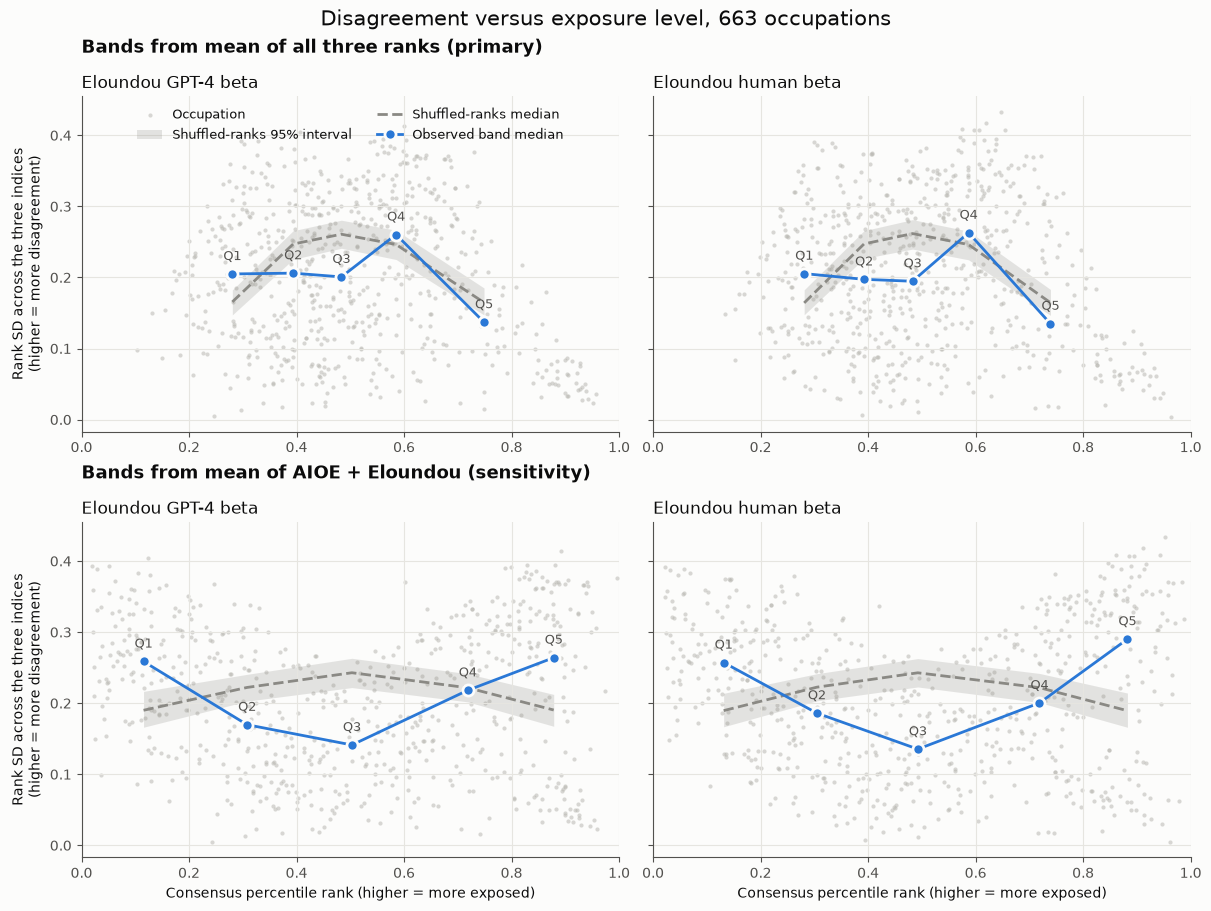

Saved ../figures/task11_disagreement_vs_exposure.png


In [7]:
figures_folder.mkdir(exist_ok=True)
SURFACE, INK, MUTED = '#fcfcfb', '#0b0b0b', '#52514e'
OBSERVED, DOTS, NULL = '#2a78d6', '#b9b8b2', '#8a8984'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
})
rule_titles = {
    'all_three': 'Bands from mean of all three ranks (primary)',
    'aioe_eloundou': 'Bands from mean of AIOE + Eloundou (sensitivity)',
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True, layout='constrained')
for r, rule in enumerate(consensus_rules):
    for c, (label_source, label) in enumerate(label_sources.items()):
        ax = axes[r, c]
        occ = occupations.loc[occupations['label_source'].eq(label_source)]
        summary = band_summary.loc[
            band_summary['label_source'].eq(label_source) & band_summary['consensus_rule'].eq(rule)
            & band_summary['metric'].eq('rank_sd')]
        x = summary['consensus_median']
        ax.scatter(occ[f'consensus_{rule}'], occ['rank_sd'], s=9, color=DOTS, alpha=0.55,
                   linewidths=0, label='Occupation')
        ax.fill_between(x, summary['null_lo'], summary['null_hi'], color=NULL, alpha=0.22,
                        linewidth=0, label='Shuffled-ranks 95% interval')
        ax.plot(x, summary['null_median'], color=NULL, linewidth=2, linestyle='--',
                label='Shuffled-ranks median')
        ax.plot(x, summary['median'], color=OBSERVED, linewidth=2, marker='o', markersize=8,
                markeredgecolor=SURFACE, markeredgewidth=2, label='Observed band median')
        for xi, yi, band in zip(x, summary['median'], summary['band']):
            ax.annotate(f'Q{band}', (xi, yi), textcoords='offset points', xytext=(0, 10),
                        ha='center', fontsize=9, color=MUTED)
        ax.set_xlim(0, 1)
        ax.set_title(f'Eloundou {label} beta', fontsize=12, loc='left')
        if c == 0:
            ax.set_ylabel('Rank SD across the three indices\n(higher = more disagreement)')
        if r == 1:
            ax.set_xlabel('Consensus percentile rank (higher = more exposed)')
    axes[r, 0].text(0, 1.13, rule_titles[rule], transform=axes[r, 0].transAxes,
                    fontsize=13, fontweight='bold')
axes[0, 0].legend(loc='upper center', fontsize=9, frameon=False, ncol=2)
fig.suptitle('Disagreement versus exposure level, 663 occupations', fontsize=15)
disagreement_path = figures_folder / 'task11_disagreement_vs_exposure.png'
fig.savefig(disagreement_path, dpi=180)
plt.show()
plt.close(fig)
print(f'Saved {disagreement_path}')

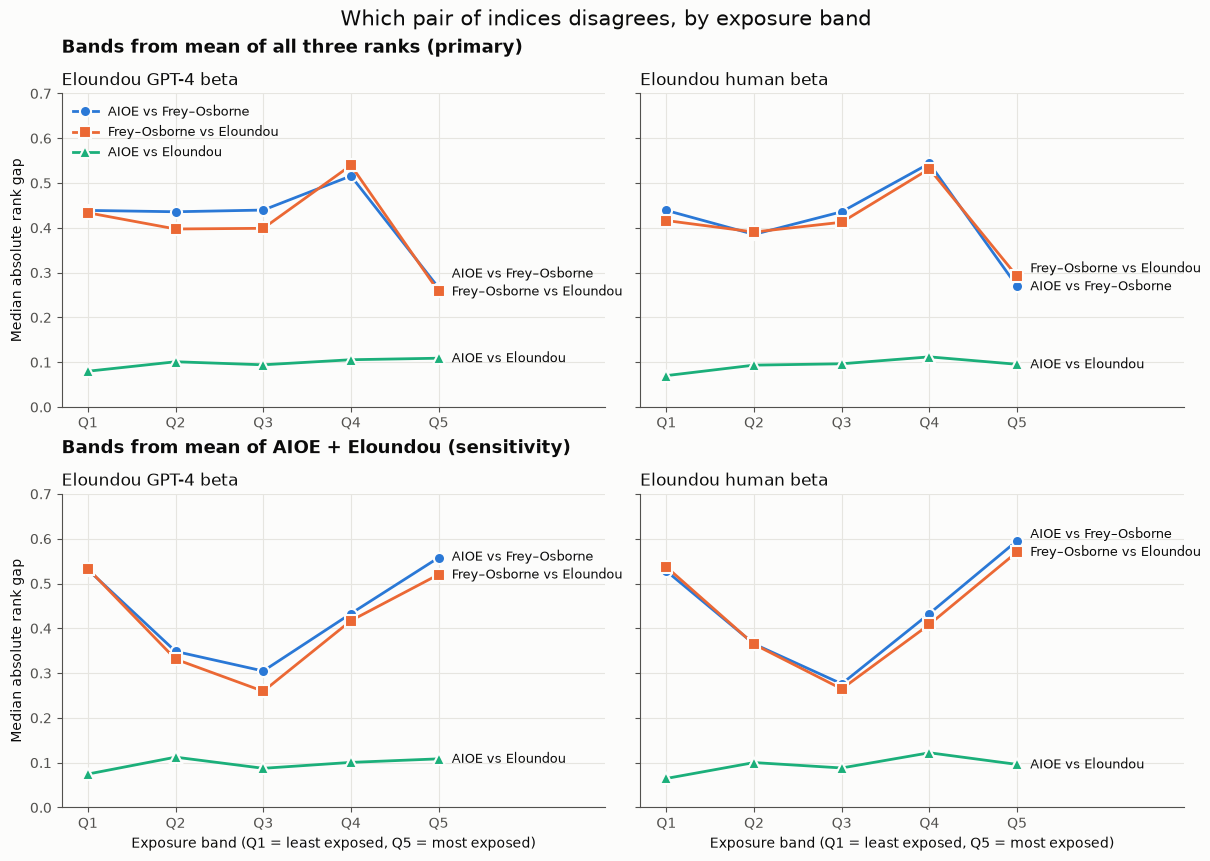

Saved ../figures/task11_pairwise_gaps_by_band.png


In [8]:
gap_styles = {
    'gap_aioe_fo': ('AIOE vs Frey–Osborne', '#2a78d6', 'o'),
    'gap_fo_elo': ('Frey–Osborne vs Eloundou', '#eb6834', 's'),
    'gap_aioe_elo': ('AIOE vs Eloundou', '#1baf7a', '^'),
}
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), sharey=True, layout='constrained')
for r, rule in enumerate(consensus_rules):
    for c, (label_source, label) in enumerate(label_sources.items()):
        ax = axes[r, c]
        subset = band_summary.loc[
            band_summary['label_source'].eq(label_source) & band_summary['consensus_rule'].eq(rule)]
        ends = {}
        for metric, (name, color, marker) in gap_styles.items():
            line = subset.loc[subset['metric'].eq(metric)]
            ax.plot(line['band'], line['median'], color=color, linewidth=2, marker=marker,
                    markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5, label=name)
            ends[name] = line['median'].iloc[-1]
        # Direct labels at Q5, nudged apart where the two Frey–Osborne lines nearly meet.
        label_y, previous = {}, -np.inf
        for name, y in sorted(ends.items(), key=lambda item: item[1]):
            label_y[name] = previous = max(y, previous + 0.04)
        for name, y in label_y.items():
            ax.annotate(name, (N_BANDS, ends[name]), xytext=(N_BANDS + 0.15, y),
                        va='center', fontsize=9, color=INK)
        ax.set_xticks(range(1, N_BANDS + 1), labels=[f'Q{b}' for b in range(1, N_BANDS + 1)])
        ax.set_xlim(0.7, N_BANDS + 1.9)
        ax.set_ylim(0, 0.7)
        ax.set_title(f'Eloundou {label} beta', fontsize=12, loc='left')
        if c == 0:
            ax.set_ylabel('Median absolute rank gap')
        if r == 1:
            ax.set_xlabel('Exposure band (Q1 = least exposed, Q5 = most exposed)')
    axes[r, 0].text(0, 1.13, rule_titles[rule], transform=axes[r, 0].transAxes,
                    fontsize=13, fontweight='bold')
axes[0, 0].legend(loc='upper left', fontsize=9, frameon=False)
fig.suptitle('Which pair of indices disagrees, by exposure band', fontsize=15)
gaps_path = figures_folder / 'task11_pairwise_gaps_by_band.png'
fig.savefig(gaps_path, dpi=180)
plt.show()
plt.close(fig)
print(f'Saved {gaps_path}')

## 6. Export and interpretation

Outputs:

- `data/datasets/processed/exposure_band_summary.csv`: the band summary from section 3.
- `data/datasets/processed/exposure_band_occupations.csv`: one row per occupation × label source, with ranks, consensus, bands, and disagreement measures. Task 12 can use it to trace individual occupations.
- `data/datasets/processed/exposure_agreement_interpretation.md`: methods, tests, and interpretation.

The interpretation text describes the pattern found on this sample. The assertions below stop execution if a rerun no longer matches that description, so the text cannot silently go out of date.

In [9]:
band_summary_path = processed_folder / 'exposure_band_summary.csv'
occupations_path = processed_folder / 'exposure_band_occupations.csv'
band_summary.to_csv(band_summary_path, index=False)
occupations.to_csv(occupations_path, index=False)

def markdown_table(frame, digits=3):
    # p-values use scientific notation so small values are not shown as 0.
    def cell(value, column):
        if not isinstance(value, (float, np.floating)):
            return str(value)
        return f'{value:.2e}' if column.endswith('_p') else f'{value:.{digits}f}'
    lines = ['| ' + ' | '.join(map(str, frame.columns)) + ' |',
             '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |']
    lines.extend('| ' + ' | '.join(cell(v, c) for v, c in zip(row, frame.columns)) + ' |'
                 for row in frame.itertuples(index=False, name=None))
    return '\n'.join(lines)

s = band_summary.set_index(['label_source', 'consensus_rule', 'band', 'metric'])
t = tests.set_index(['label_source', 'consensus_rule'])
sd = lambda src, rule, band, col='median': s.loc[(src, rule, band, 'rank_sd'), col]
gap = lambda src, rule, band, pair: s.loc[(src, rule, band, pair), 'median']

# The interpretation below depends on these holding for both label sources.
for src in label_sources:
    assert s.loc[(src, 'all_three', N_BANDS, 'rank_sd'), 'vs_null'] == 'below'
    assert s.loc[(src, 'all_three', 1, 'rank_sd'), 'vs_null'] == 'above'
    assert abs(t.loc[(src, 'all_three'), 'spearman_rho']) < 0.1
    assert sd(src, 'all_three', N_BANDS) == min(sd(src, 'all_three', b) for b in range(1, N_BANDS + 1))
    assert s.loc[(src, 'aioe_eloundou', N_BANDS, 'rank_sd'), 'vs_null'] == 'above'
    for rule in consensus_rules:
        for band in range(1, N_BANDS + 1):
            assert gap(src, rule, band, 'gap_aioe_elo') < min(
                gap(src, rule, band, 'gap_aioe_fo'), gap(src, rule, band, 'gap_fo_elo'))

def by_band(src, rule):
    return ', '.join(f'{sd(src, rule, b):.3f}' for b in range(1, N_BANDS + 1))

ae_gaps = band_summary.loc[band_summary['metric'].eq('gap_aioe_elo'), 'median']
fo_gaps = band_summary.loc[band_summary['metric'].isin(['gap_aioe_fo', 'gap_fo_elo']), 'median']
flagged = band_summary.loc[band_summary['metric'].eq('rank_sd') & band_summary['tie_heavy_flag'],
                           ['label_source', 'consensus_rule', 'band']]
flag_text = ('; '.join(f'{r.label_source}/{r.consensus_rule}/Q{r.band}' for r in flagged.itertuples())
             or 'none')
assert set(flagged['band']) == {1}, 'Interpretation assumes only Q1 is tie-heavy'

sd_table = band_summary.loc[band_summary['metric'].eq('rank_sd'),
    ['label_source', 'consensus_rule', 'band', 'n', 'consensus_min', 'consensus_max',
     'median', 'q1', 'q3', 'null_lo', 'null_hi', 'vs_null', 'tie_heavy_flag']]
test_table = tests[['label_source', 'consensus_rule', 'spearman_rho', 'spearman_p', 'kruskal_p',
                    'top_band_median_sd', 'other_bands_median_sd', 'mannwhitney_p',
                    'top_null_lo', 'top_null_hi', 'top_vs_null']]

report = '\n\n'.join([
    '# Task 11 — Agreement versus exposure level',
    f'Input: `agreement_analysis_sample.csv`; SHA-256: `{source_sha256}`. '
    'Notebook: `notebooks/task11.ipynb`. Figures: `figures/task11_disagreement_vs_exposure.png`, '
    '`figures/task11_pairwise_gaps_by_band.png`.',
    '## Methods',
    'All results use the same 663 occupations from Task 9 and the saved beta percentile ranks, '
    'run once with Eloundou GPT-4 labels and once with human labels. No scores are imputed or weighted.',
    f'**Band rule.** Consensus is the unweighted mean of an occupation\'s percentile ranks. '
    f'Occupations are sorted by consensus and split into {N_BANDS} equal-count bands '
    '(133, 133, 133, 132, 132); exact ties are broken by SOC code. The primary rule averages all three '
    'indices. A sensitivity rule averages AIOE and Eloundou only, because Frey–Osborne is negatively '
    'correlated with both (Task 10).',
    '**Disagreement.** Per occupation: standard deviation of the three ranks, range, and the three '
    'pairwise absolute rank gaps. Band summaries report medians and quartiles.',
    f'**Baseline.** Bounded ranks make spread mechanically smaller in the extreme bands. Each index\'s '
    f'ranks were shuffled independently {N_PERMUTATIONS} times (seed {SEED}) and bands recomputed; the '
    '2.5th–97.5th percentiles of the shuffled band medians are the no-agreement baseline.',
    f'**Flags.** A band is sparse if it has fewer than {MIN_BAND_SIZE} occupations (none are). '
    f'A band is tie-heavy if, for any one index, more than {TIE_HEAVY_SHARE:.0%} of its occupations share '
    'a single raw score. '
    'Tie-heavy bands: ' + flag_text + '.',
    '## Rank SD by band',
    markdown_table(sd_table),
    '## Tests',
    markdown_table(test_table, digits=4),
    'p-values are unadjusted and descriptive. The Kruskal–Wallis and Mann–Whitney tests compare observed '
    'bands with each other and so include the ceiling effect; the baseline columns account for it.',
    '## Interpretation',
    f'**Under the primary rule, disagreement does not rise among the most-exposed occupations; it falls.** '
    f'Median rank SD by band (Q1→Q5) is {by_band("gpt4", "all_three")} with GPT-4 labels and '
    f'{by_band("human", "all_three")} with human labels. The top band is the most consistent of the five '
    f'and sits below the shuffled baseline ({sd("gpt4", "all_three", N_BANDS, "null_lo"):.3f}–'
    f'{sd("gpt4", "all_three", N_BANDS, "null_hi"):.3f}), so the three indices agree on these occupations '
    'more than chance alone would produce, even after allowing for the ceiling effect. Disagreement peaks '
    'in Q4 instead, and the least-exposed band (Q1) is the only one above its baseline. Because the '
    'pattern is not monotonic, the overall Spearman correlation between consensus and rank SD is near zero '
    f'({t.loc[("gpt4", "all_three"), "spearman_rho"]:.3f} GPT-4; '
    f'{t.loc[("human", "all_three"), "spearman_rho"]:.3f} human). '
    'The conclusion is the same for GPT-4 and human labels.',
    f'**That result depends on how exposure is defined, and Frey–Osborne drives nearly all of the '
    f'disagreement.** The AIOE–Eloundou gap stays small in every band (medians '
    f'{ae_gaps.min():.3f}–{ae_gaps.max():.3f}), while the two Frey–Osborne gaps are several times larger '
    f'({fo_gaps.min():.3f}–{fo_gaps.max():.3f}). When bands are built from AIOE and Eloundou only, the '
    f'most-exposed band has the *highest* median rank SD ({sd("gpt4", "aioe_eloundou", N_BANDS):.3f} GPT-4; '
    f'{sd("human", "aioe_eloundou", N_BANDS):.3f} human), above the shuffled baseline. Those are '
    'occupations both modern indices rank as highly exposed to AI that Frey–Osborne ranks as low '
    'computerisation risk. So "disagreement is greatest at the high-exposure end" holds only when exposure '
    'means modern AI exposure, and the disagreement is between the older computerisation measure and the '
    'two modern ones. It is not disagreement among the modern indices.',
    f'**Caveats.** Bands are equal-count quintiles of an unweighted consensus, so their boundaries depend '
    'on which indices enter the consensus. Q1 is tie-heavy under every rule and label source: about a third '
    'of its occupations have an Eloundou score of exactly 0 and therefore share one average rank, so Q1 '
    'gaps partly reflect where that tied block lands rather than fine-grained disagreement. Frey–Osborne '
    'is also coarse (181 distinct values across 663 occupations). The tests are associations across occupations, unadjusted for '
    'multiple comparisons; they do not show that exposure causes disagreement, and none of these '
    'indices is a forecast of job loss.',
])
interpretation_path = processed_folder / 'exposure_agreement_interpretation.md'
interpretation_path.write_text(report + '\n')
for path in [band_summary_path, occupations_path, interpretation_path]:
    print(f'Saved {path}')

Saved ../data/datasets/processed/exposure_band_summary.csv
Saved ../data/datasets/processed/exposure_band_occupations.csv
Saved ../data/datasets/processed/exposure_agreement_interpretation.md
